In [22]:
# 1. Imports and check scraped data
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

if "df" not in globals():
    df = pd.read_csv("/content/Cleaned Dataset .csv")

df.columns = df.columns.str.strip()
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset shape: (984, 19)


,productname,price,rating,features,pagenum,original_price,Discount,Review,Price_INR,Original_Price_INR,Discount_Percent,Rating,Product_Name,Features_Text,Brand,Processor,RAM_GB,SSD_GB,Display_inches
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,"₹62,990",4.4,Intel Core i5 Processor (13th Gen)16 GB LPDDR4...,1,"₹82,789",23% off,"21,838 Ratings & 2,331 Reviews",62990.0,82789.0,23.0,4.4,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5,16.0,512.0,15.6
1,HP 15 (i5 14th Gen) Intel Core 5 120U - (24 GB...,"₹77,990",4.1,Intel Core 5 Processor24 GB DDR5 RAMWindows 11...,1,"₹1,32,489",41% off,825 Ratings & 69 Reviews,77990.0,132489.0,41.0,4.1,HP 15 (i5 14th Gen) Intel Core 5 120U - (24 GB...,HP 15 (i5 14th Gen) Intel Core 5 120U - (24 GB...,HP,Intel Core 5 120U,24.0,512.0,15.6
2,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,"₹62,990",4.4,Intel Core i5 Processor (13th Gen)16 GB LPDDR4...,1,"₹82,789",23% off,"21,838 Ratings & 2,331 Reviews",62990.0,82789.0,23.0,4.4,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5,16.0,512.0,15.6
3,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,"₹74,990",4.4,Intel Core 5 Processor16 GB DDR4 RAM64 bit Win...,1,"₹1,20,990",38% off,"2,129 Ratings & 217 Reviews",74990.0,120990.0,38.0,4.4,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,ASUS,Intel Core 5 210H,16.0,512.0,14.0
4,HP Victus Intel Core i5 13th Gen 13420 H - (16...,"₹1,02,990",4.3,Intel Core i5 Processor (13th Gen)16 GB DDR4 R...,1,"₹1,54,920",33% off,519 Ratings & 32 Reviews,102990.0,154920.0,33.0,4.3,HP Victus Intel Core i5 13th Gen 13420 H - (16...,HP Victus Intel Core i5 13th Gen 13420 H - (16...,HP,Intel Core i5,16.0,512.0,15.6


Columns: ['productname', 'price', 'rating', 'features', 'pagenum', 'original_price', 'Discount', 'Review', 'Price_INR', 'Original_Price_INR', 'Discount_Percent', 'Rating', 'Product_Name', 'Features_Text', 'Brand', 'Processor', 'RAM_GB', 'SSD_GB', 'Display_inches']


In [23]:
# 2. Clean text and convert price/discount/rating values

def parse_money(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r"[^0-9.]", "", str(value).replace(",", ""))
    return pd.to_numeric(text, errors="coerce")

def parse_percent(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"(\d+(?:\.\d+)?)", str(value))
    return float(match.group(1)) if match else np.nan

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()


for col in ["productname", "features", "price", "original_price", "Discount", "rating", "Review"]:
    if col not in df.columns:
        df[col] = np.nan

df["Price_INR"] = df["price"].apply(parse_money)
df["Original_Price_INR"] = df["original_price"].apply(parse_money)
df["Discount_Percent"] = df["Discount"].apply(parse_percent)
df["Rating"] = pd.to_numeric(
    df["rating"].astype(str).str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

df["Product_Name"] = df["productname"].fillna("").astype(str).str.strip()
df["Features_Text"] = (
    df["Product_Name"] + " " + df["features"].fillna("").astype(str)
).str.strip()

print("Missing values before duplicate handling:")
display(df[["Product_Name", "Price_INR", "Original_Price_INR", "Discount_Percent", "Rating"]].isna().sum())

Missing values before duplicate handling:


,0
Product_Name,0
Price_INR,16
Original_Price_INR,51
Discount_Percent,66
Rating,117


In [24]:
# 3. Feature extraction: Brand, Processor, RAM, SSD and Display

KNOWN_BRANDS = [
    "Microsoft", "Primebook", "Zebronics", "Samsung", "Infinix",
    "Lenovo", "Fujitsu", "Thomson", "Colorful", "Motorola",
    "Gigabyte", "Xiaomi", "Realme", "Chuwi", "ULTIMUS",
    "ASUS", "Acer", "Apple", "Dell", "Honor", "Avita",
    "Wings", "Vaio", "HP", "MSI", "LG", "Mi", "Jio"
]

def extract_brand(name):
    name = str(name).strip()
    for brand in sorted(KNOWN_BRANDS, key=len, reverse=True):
        if name.lower().startswith(brand.lower()):
            return brand
    return name.split()[0] if name else "Unknown"

def extract_processor(text):
    patterns = [
        r"Intel\s+Core\s+Ultra\s*[3579](?:\s+\w+)?",
        r"Intel\s+Core\s+i[3579](?:\s*[- ]?\s*\d{4,5}[A-Z]{0,2})?",
        r"Intel\s+Core\s+[3579](?:\s+\d{3,5}[A-Z]{0,2})?",
        r"Intel\s+Processor\s+N\d{3,4}",
        r"Intel\s+Celeron(?:\s+N?\d{3,4})?",
        r"Intel\s+Pentium(?:\s+Gold)?",
        r"AMD\s+Ryzen\s+[3579](?:\s+\d{4}[A-Z]{0,2})?",
        r"Ryzen\s+[3579]",
        r"Apple\s+M[12345](?:\s+(?:Pro|Max|Ultra))?",
        r"Snapdragon\s+X(?:\s+Plus|\s+Elite)?",
        r"AMD\s+Athlon(?:\s+Silver)?"
    ]
    for pattern in patterns:
        match = re.search(pattern, str(text), flags=re.IGNORECASE)
        if match:
            return re.sub(r"\s+", " ", match.group(0)).strip()
    return "Not specified"

def extract_ram(text):

    patterns = [
        r"(\d{1,3})\s*GB\s*(?:DDR\d?X?|LPDDR\d?X?)\s*(?:RAM|Memory)?\b",
        r"(\d{1,3})\s*GB\s*(?:RAM|Memory)\b",
        r"(?:RAM|Memory)\s*[:\-]?\s*(\d{1,3})\s*GB\b"
    ]
    for pattern in patterns:
        match = re.search(pattern, str(text), flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return np.nan

def extract_ssd(text):
    patterns = [
        r"(\d+(?:\.\d+)?)\s*(TB|GB)\s*(?:NVMe\s*)?SSD\b",
        r"SSD\s*(\d+(?:\.\d+)?)\s*(TB|GB)\b"
    ]
    for pattern in patterns:
        match = re.search(pattern, str(text), flags=re.IGNORECASE)
        if match:
            value = float(match.group(1))
            unit = match.group(2).upper()
            return int(value * 1024) if unit == "TB" else int(value)
    return np.nan

def extract_display(text):
    patterns = [
        r"\d{2}(?:\.\d+)?\s*cm\s*\(\s*(\d{1,2}(?:\.\d+)?)\s*(?:inch|inches)",
        r"(\d{1,2}(?:\.\d+)?)\s*(?:inch|inches)\b"
    ]
    for pattern in patterns:
        match = re.search(pattern, str(text), flags=re.IGNORECASE)
        if match:
            return float(match.group(1))
    return np.nan

df["Brand"] = df["Product_Name"].apply(extract_brand)
df["Processor"] = df["Features_Text"].apply(extract_processor)
df["RAM_GB"] = df["Features_Text"].apply(extract_ram)
df["SSD_GB"] = df["Features_Text"].apply(extract_ssd)
df["Display_inches"] = df["Features_Text"].apply(extract_display)

display(df[[
    "Product_Name", "Brand", "Processor", "RAM_GB",
    "SSD_GB", "Display_inches", "Price_INR",
    "Discount_Percent", "Rating"
]].head(10))

,Product_Name,Brand,Processor,RAM_GB,SSD_GB,Display_inches,Price_INR,Discount_Percent,Rating
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5,16.0,512.0,15.6,62990.0,23.0,4.4
1,HP 15 (i5 14th Gen) Intel Core 5 120U - (24 GB...,HP,Intel Core 5 120U,24.0,512.0,15.6,77990.0,41.0,4.1
2,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5,16.0,512.0,15.6,62990.0,23.0,4.4
3,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,ASUS,Intel Core 5 210H,16.0,512.0,14.0,74990.0,38.0,4.4
4,HP Victus Intel Core i5 13th Gen 13420 H - (16...,HP,Intel Core i5,16.0,512.0,15.6,102990.0,33.0,4.3
5,Lenovo 100e Chromebook Gen 4 MediaTek Kompanio...,Lenovo,Not specified,4.0,NaN,11.6,18490.0,14.0,4.0
6,Acer Aspire Lite Metal (2026) AMD Ryzen 3 Quad...,Acer,AMD Ryzen 3,8.0,512.0,15.6,42990.0,14.0,4.1
7,Acer Chromebook MediaTek Kompanio 540 - (4 GB/...,Acer,Not specified,4.0,NaN,15.6,26990.0,49.0,NaN
8,DELL 15 AMD Ryzen 5 Quad Core 7520U - (8 GB/51...,Dell,AMD Ryzen 5,8.0,512.0,15.6,57990.0,3.0,4.2
9,Primebook Wifi (2026 Model) MediaTek MT8183 - ...,Primebook,Not specified,4.0,NaN,11.6,14990.0,50.0,4.1


In [25]:
# 4. Create final cleaned dataset and handle duplicates
cleaned = df[[
    "Product_Name", "Brand", "Processor", "RAM_GB", "SSD_GB",
    "Display_inches", "Price_INR", "Original_Price_INR",
    "Discount_Percent", "Rating", "Review"
]].copy()

cleaned = cleaned.replace(r"^\s*$", np.nan, regex=True)
rows_before = len(cleaned)
cleaned = cleaned.drop_duplicates(
    subset=["Product_Name", "Price_INR"], keep="first"
).reset_index(drop=True)


cleaned["Discount_Amount_INR"] = (
    cleaned["Original_Price_INR"] - cleaned["Price_INR"]
)
cleaned.loc[cleaned["Discount_Amount_INR"] < 0, "Discount_Amount_INR"] = np.nan

cleaned["Price_Category"] = pd.cut(
    cleaned["Price_INR"],
    bins=[0, 30000, 50000, 80000, np.inf],
    labels=["Budget", "Mid-range", "High-end", "Premium"],
    include_lowest=True
)

cleaned["RAM_Category"] = pd.cut(
    cleaned["RAM_GB"],
    bins=[0, 8, 16, 32, np.inf],
    labels=["8 GB or less", "9–16 GB", "17–32 GB", "Above 32 GB"]
)

cleaned["SSD_Category"] = pd.cut(
    cleaned["SSD_GB"],
    bins=[0, 256, 512, 1024, np.inf],
    labels=["Up to 256 GB", "257–512 GB", "513 GB–1 TB", "Above 1 TB"]
)

cleaned["Premium_Laptop"] = np.where(
    cleaned["Price_INR"].ge(80000), "Yes", "No"
)

print(f"Rows before duplicate removal: {rows_before}")
print(f"Rows after duplicate removal: {len(cleaned)}")
print(f"Duplicate records removed: {rows_before - len(cleaned)}")
print("\nMissing values after extraction:")
display(cleaned.isna().sum().to_frame("Missing_Count"))
cleaned.to_csv("flipkart_laptop_cleaned.csv", index=False)
print("Saved: flipkart_laptop_cleaned.csv")

Rows before duplicate removal: 984
Rows after duplicate removal: 539
Duplicate records removed: 445

Missing values after extraction:


,Missing_Count
Product_Name,0
Brand,0
Processor,0
RAM_GB,25
SSD_GB,61
Display_inches,0
Price_INR,16
Original_Price_INR,48
Discount_Percent,62
Rating,104


Saved: flipkart_laptop_cleaned.csv


In [26]:
# 5. EDA summary tables

def comparison_table(column):
    return (
        cleaned.groupby(column, dropna=False, observed=True)
        .agg(
            Laptop_Count=("Product_Name", "count"),
            Average_Price_INR=("Price_INR", "mean"),
            Median_Price_INR=("Price_INR", "median"),
            Average_Rating=("Rating", "mean"),
            Average_Discount_Percent=("Discount_Percent", "mean")
        )
        .round(2)
        .sort_values("Laptop_Count", ascending=False)
        .reset_index()
    )

processor_comparison = comparison_table("Processor")
ram_comparison = comparison_table("RAM_GB")
ssd_comparison = comparison_table("SSD_GB")
brand_comparison = comparison_table("Brand")

print("PROCESSOR COMPARISON")
display(processor_comparison)

print("RAM COMPARISON")
display(ram_comparison)

print("SSD COMPARISON")
display(ssd_comparison)

print("BRAND COMPARISON")
display(brand_comparison)

premium_laptops = (
    cleaned[cleaned["Premium_Laptop"] == "Yes"]
    .sort_values("Price_INR", ascending=False)
)
print("PREMIUM LAPTOPS (₹80,000 and above)")
display(premium_laptops.head(30))

PROCESSOR COMPARISON


,Processor,Laptop_Count,Average_Price_INR,Median_Price_INR,Average_Rating,Average_Discount_Percent
0,Intel Core i5,92,80982.15,75410.5,4.14,13.88
1,Intel Core i3,63,56006.75,55990.0,4.10,16.63
2,AMD Ryzen 5,56,67357.47,62990.0,4.22,16.50
3,AMD Ryzen 3,52,51944.42,50990.0,4.07,19.30
4,Not specified,25,104741.96,43740.0,4.24,32.36
...,...,...,...,...,...,...
67,Intel Core Ultra 9 290HX,1,290000.00,290000.0,4.60,22.00
68,Intel Core Ultra 7 Series,1,114990.00,114990.0,3.00,48.00
69,Intel Core i7 1360P,1,99890.00,99890.0,4.90,12.00
70,Intel Core i9,1,139533.00,139533.0,NaN,6.00


RAM COMPARISON


,RAM_GB,Laptop_Count,Average_Price_INR,Median_Price_INR,Average_Rating,Average_Discount_Percent
0,16.0,242,100758.99,82990.0,4.20,20.29
1,8.0,216,55406.12,55155.0,4.13,20.87
2,NaN,25,228090.40,209900.0,4.76,9.00
3,4.0,18,28229.50,26990.0,3.97,30.29
4,32.0,15,257457.64,253094.5,4.24,19.17
5,12.0,11,63259.80,63804.5,3.97,20.20
6,24.0,10,127830.00,96490.0,4.26,28.38
7,64.0,2,339990.00,339990.0,4.90,23.50


SSD COMPARISON


,SSD_GB,Laptop_Count,Average_Price_INR,Median_Price_INR,Average_Rating,Average_Discount_Percent
0,512.0,381,77221.49,67714.5,4.17,20.48
1,NaN,61,82652.02,64990.0,4.18,25.11
2,1024.0,55,185775.57,177945.0,4.40,14.06
3,256.0,37,51271.86,42895.0,4.14,26.15
4,2048.0,5,451918.00,399900.0,NaN,13.00


BRAND COMPARISON


,Brand,Laptop_Count,Average_Price_INR,Median_Price_INR,Average_Rating,Average_Discount_Percent
0,HP,136,72951.23,63490.0,4.10,15.73
1,ASUS,126,104194.83,77317.0,4.34,24.20
2,Lenovo,96,93410.59,69990.0,4.14,20.94
3,Acer,85,54264.61,47448.5,4.04,28.32
4,Dell,45,91530.05,74504.0,4.11,12.66
5,Apple,26,223544.62,209900.0,4.75,9.00
6,Primebook,6,27990.00,28990.0,4.22,37.67
7,Microsoft,6,157754.00,143886.0,4.40,2.00
8,MSI,5,67779.50,69164.5,4.20,19.25
9,Samsung,4,82743.75,73490.0,4.48,20.00


PREMIUM LAPTOPS (₹80,000 and above)


,Product_Name,Brand,Processor,RAM_GB,SSD_GB,Display_inches,Price_INR,Original_Price_INR,Discount_Percent,Rating,Review,Discount_Amount_INR,Price_Category,RAM_Category,SSD_Category,Premium_Laptop
462,"Apple MacBook Pro (M5 Max, 2026) M5 Max - (48 ...",Apple,Apple M5 Max,NaN,2048.0,16.0,619900.0,NaN,NaN,NaN,<NA>,NaN,Premium,NaN,Above 1 TB,Yes
470,Lenovo Intel Core Ultra 9 275HX - (32 GB/1 TB ...,Lenovo,Intel Core Ultra 9 275HX,32.0,1024.0,16.0,611890.0,NaN,NaN,NaN,<NA>,NaN,Premium,17–32 GB,513 GB–1 TB,Yes
466,ASUS ROG Zephyrus G16 OLED (2026) Intel Core U...,ASUS,Intel Core Ultra 9 386H,32.0,2048.0,16.0,529990.0,611990.0,13.0,NaN,<NA>,82000.0,Premium,17–32 GB,Above 1 TB,Yes
446,Lenovo Legion 5 (2026) WQXGA OLED Intel Core U...,Lenovo,Intel Core Ultra 7 356H,16.0,512.0,15.3,422890.0,NaN,NaN,NaN,<NA>,NaN,Premium,9–16 GB,257–512 GB,Yes
483,"Apple MacBook Pro (M5 Pro, 2026) M5 Pro - (24 ...",Apple,Apple M5 Pro,NaN,2048.0,14.0,399900.0,NaN,NaN,NaN,<NA>,NaN,Premium,NaN,Above 1 TB,Yes
399,"Apple MacBook Pro (M5 Max, 2026) M5 Max - (36 ...",Apple,Apple M5 Max,NaN,2048.0,14.0,399900.0,NaN,NaN,NaN,<NA>,NaN,Premium,NaN,Above 1 TB,Yes
464,Lenovo Legion 5 Intel Core i7 13th Gen 13650HX...,Lenovo,Intel Core i7,16.0,512.0,15.3,350890.0,NaN,NaN,NaN,<NA>,NaN,Premium,9–16 GB,257–512 GB,Yes
89,ASUS ExpertBook Ultra Full Metal Nano Ceramic ...,ASUS,Not specified,64.0,NaN,14.0,349990.0,389990.0,10.0,4.8,43 Ratings & 8 Reviews,40000.0,Premium,Above 32 GB,NaN,Yes
425,"Apple MacBook Pro (M5 Pro, 2026) M5 Pro - (24 ...",Apple,Apple M5 Pro,NaN,1024.0,16.0,342490.0,359900.0,4.0,NaN,<NA>,17410.0,Premium,NaN,513 GB–1 TB,Yes
166,ASUS ROG Flow Z13 (2025) for Creator with Touc...,ASUS,Not specified,64.0,NaN,13.4,329990.0,527990.0,37.0,5.0,3 Ratings & 1 Reviews,198000.0,Premium,Above 32 GB,NaN,Yes


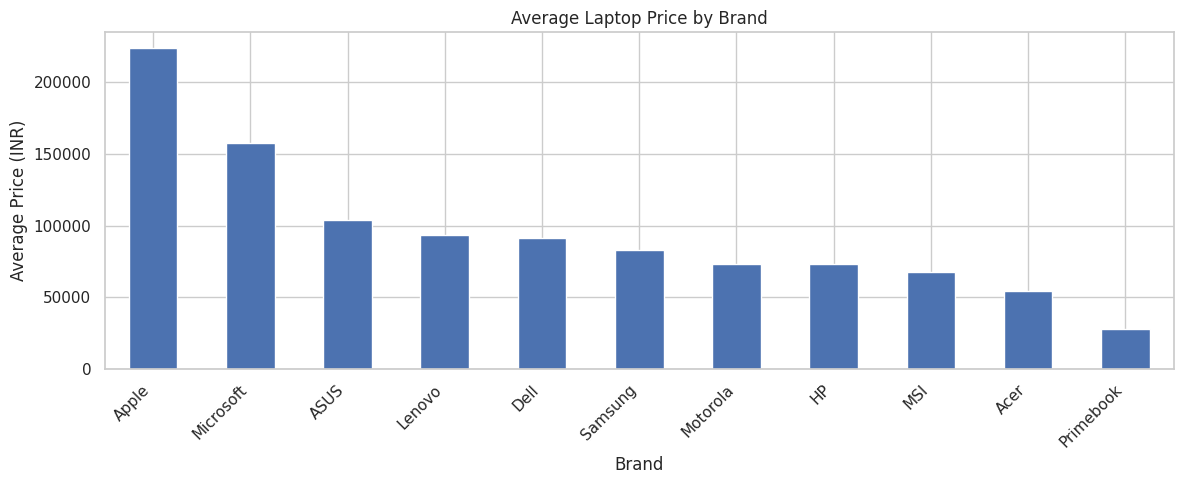

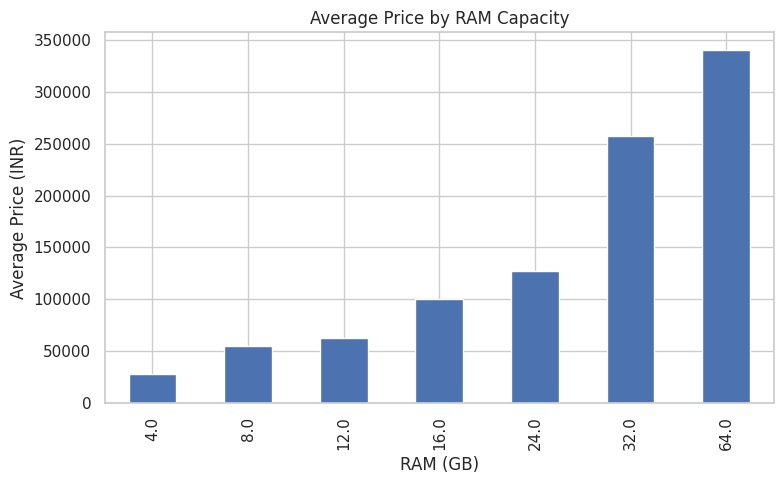

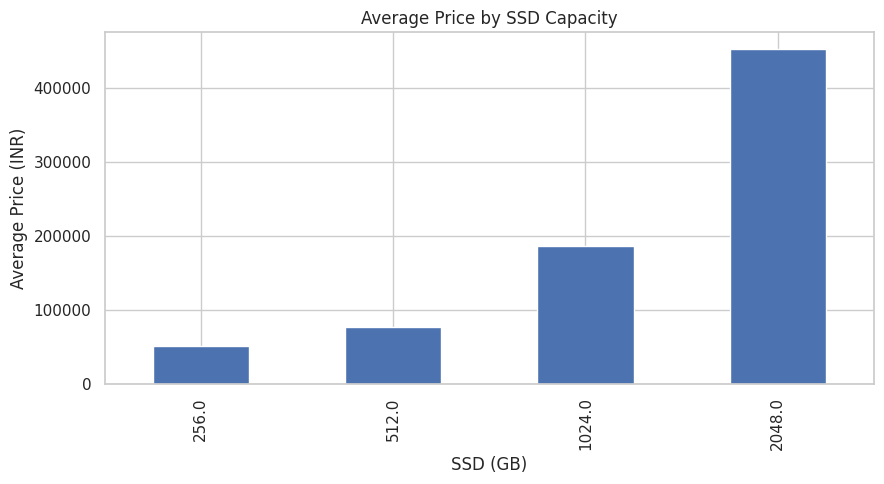

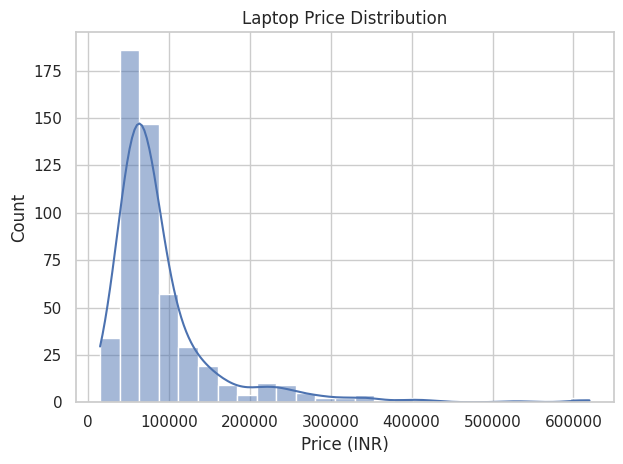

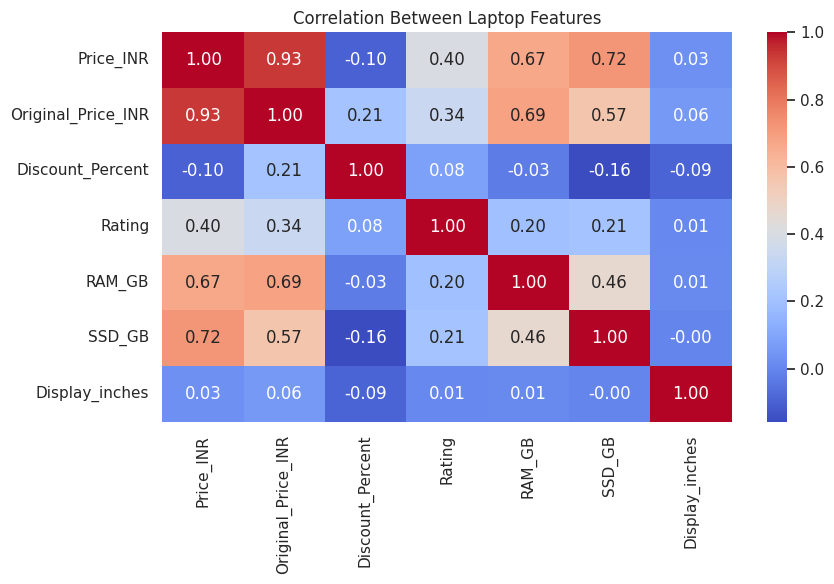

In [27]:
# 6. Visual EDA

sns.set_theme(style="whitegrid")

brand_chart_data = (
    cleaned.dropna(subset=["Price_INR"])
    .groupby("Brand")
    .agg(Average_Price=("Price_INR", "mean"), Count=("Product_Name", "size"))
)
brand_chart_data = brand_chart_data[brand_chart_data["Count"] >= 3]
brand_chart_data = brand_chart_data.sort_values("Average_Price", ascending=False)

if not brand_chart_data.empty:
    ax = brand_chart_data["Average_Price"].plot(
        kind="bar", figsize=(12, 5), title="Average Laptop Price by Brand"
    )
    ax.set_ylabel("Average Price (INR)")
    ax.set_xlabel("Brand")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

ram_chart_data = cleaned.dropna(subset=["RAM_GB", "Price_INR"]).groupby("RAM_GB")["Price_INR"].mean()
if not ram_chart_data.empty:
    ram_chart_data.sort_index().plot(
        kind="bar", figsize=(8, 5), title="Average Price by RAM Capacity"
    )
    plt.ylabel("Average Price (INR)")
    plt.xlabel("RAM (GB)")
    plt.tight_layout()
    plt.show()

ssd_chart_data = cleaned.dropna(subset=["SSD_GB", "Price_INR"]).groupby("SSD_GB")["Price_INR"].mean()
if not ssd_chart_data.empty:
    ssd_chart_data.sort_index().plot(
        kind="bar", figsize=(9, 5), title="Average Price by SSD Capacity"
    )
    plt.ylabel("Average Price (INR)")
    plt.xlabel("SSD (GB)")
    plt.tight_layout()
    plt.show()

if cleaned["Price_INR"].notna().any():
    sns.histplot(cleaned["Price_INR"].dropna(), bins=25, kde=True)
    plt.title("Laptop Price Distribution")
    plt.xlabel("Price (INR)")
    plt.tight_layout()
    plt.show()

numeric_cols = [
    "Price_INR", "Original_Price_INR", "Discount_Percent",
    "Rating", "RAM_GB", "SSD_GB", "Display_inches"
]
corr = cleaned[numeric_cols].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Laptop Features")
plt.tight_layout()
plt.show()

In [28]:
# 7. Business insights (generated from actual dataset values)

valid_prices = cleaned.dropna(subset=["Price_INR"])

if not valid_prices.empty:
    print(f"Average listed price: ₹{valid_prices['Price_INR'].mean():,.0f}")
    print(f"Median listed price: ₹{valid_prices['Price_INR'].median():,.0f}")
    print(f"Premium laptop count (₹80,000+): {(valid_prices['Price_INR'] >= 80000).sum()}")

    brand_stats = (
        valid_prices.groupby("Brand")
        .agg(Count=("Product_Name", "size"), Average_Price=("Price_INR", "mean"))
    )
    brand_stats = brand_stats[brand_stats["Count"] >= 3]

    if not brand_stats.empty:
        print("\nMost represented brands in this dataset:")
        display(brand_stats.sort_values("Count", ascending=False).head(5).round(2))

        print("\nHighest average-price brands with at least 3 listings:")
        display(brand_stats.sort_values("Average_Price", ascending=False).head(5).round(2))

    rated = valid_prices.dropna(subset=["Rating"])
    if not rated.empty:
        print("\nHighest-rated affordable candidates (rating >= 4, price ascending):")
        display(
            rated[rated["Rating"] >= 4]
            .sort_values(["Price_INR", "Rating"], ascending=[True, False])
            [[ "Product_Name", "Brand", "Processor", "RAM_GB",
               "SSD_GB", "Price_INR", "Rating" ]]
            .head(10)
        )

print("\nBusiness recommendations:")
print("1. Compare prices within the same processor and RAM category before setting prices.")
print("2. Use discount campaigns selectively; verify original prices and discount values.")
print("3. Keep a balanced assortment of budget, mid-range, high-end and premium laptops.")
print("4. Recommend value-for-money products using both price and rating, not price alone.")
print("5. Treat brand counts as representation in this collected dataset, not market share.")

Average listed price: ₹90,789
Median listed price: ₹69,890
Premium laptop count (₹80,000+): 178

Most represented brands in this dataset:


,Count,Average_Price
Brand,,
HP,132,72951.23
ASUS,122,104194.83
Lenovo,95,93410.59
Acer,80,54264.61
Dell,44,91530.05



Highest average-price brands with at least 3 listings:


,Count,Average_Price
Brand,,
Apple,26,223544.62
Microsoft,6,157754.00
ASUS,122,104194.83
Lenovo,95,93410.59
Dell,44,91530.05



Highest-rated affordable candidates (rating >= 4, price ascending):


,Product_Name,Brand,Processor,RAM_GB,SSD_GB,Price_INR,Rating
8,Primebook Wifi (2026 Model) MediaTek MT8183 - ...,Primebook,Not specified,4.0,NaN,14990.0,4.1
4,Lenovo 100e Chromebook Gen 4 MediaTek Kompanio...,Lenovo,Not specified,4.0,NaN,18490.0,4.0
246,Lenovo IdeaPad 3 Intel Celeron Dual Core N4020...,Lenovo,Intel Celeron,4.0,256.0,27990.0,4.4
60,Primebook 2 Max (2026) in-Built AI MediaTek He...,Primebook,Not specified,8.0,NaN,27990.0,4.1
24,Primebook 2 Pro (2026) in-Built AI MediaTek He...,Primebook,Not specified,8.0,NaN,28490.0,4.3
81,Primebook 2 Max (2026) in-Built AI MediaTek He...,Primebook,Not specified,8.0,NaN,29490.0,4.1
48,Primebook 2 Max (2026) in-Built AI MediaTek He...,Primebook,Not specified,8.0,NaN,31490.0,4.3
59,ASUS Chromebook CX15 Intel Celeron Dual Core N...,ASUS,Intel Celeron,4.0,NaN,32985.0,4.0
299,Lenovo IdeaPad 3 Intel Intel Core i3 10th Gen ...,Lenovo,Intel Core i3,8.0,256.0,34990.0,5.0
326,Lenovo IdeaPad 3 Intel Intel Core i3 10th Gen ...,Lenovo,Intel Core i3,4.0,256.0,34990.0,5.0



Business recommendations:
1. Compare prices within the same processor and RAM category before setting prices.
2. Use discount campaigns selectively; verify original prices and discount values.
3. Keep a balanced assortment of budget, mid-range, high-end and premium laptops.
4. Recommend value-for-money products using both price and rating, not price alone.
5. Treat brand counts as representation in this collected dataset, not market share.
